# Synthetic moment PDFs — moment 0 and moment 1
Adapted from the 30 Dor histogram example for the synthetic moments pipeline.

**One 1×2 figure per N = 64, 128, 256:** left = moment 0, right = moment 1. Each panel overlays σE = 0, 1, 2 with the same colors as the structure-function visualizer.

Set `DATA_ROOT`, then run all cells. Input filenames follow `stable_alpha1.5_moments_N256_L16_sigE0.fits`. Subfolders are searched. `MOM0` and `MOM1` must be 2D images. If `MASK` exists, finite nonzero mask values mean valid pixels; otherwise all pixels are initially admitted. Each moment then receives its own finite-value filter; log-brightness modes also require positive moment 0.

Defaults follow your example: moment 0 shows $\log_{10}[I/\mathrm{median}(I)]$ and moment 1 shows $V-\langle V\rangle$. Normalization and centering are computed **separately for each sample**. Change the configuration to show raw values. Probability densities integrate to one over the plotted variable (log-brightness density is per dex); optional counts are also available. All samples share bin edges for each moment, including across N. No percentile clipping is applied.

Velocity statistics use `ddof=0`, consistent with `np.var(vv)` in your synthetic pipeline. Statistics in the velocity legend refer to the original velocity map, even when the plotted velocities are centered. Moment-0 statistics refer to the transformed quantity plotted. σE = 0 may give nearly uniform moment 0, producing a narrow histogram whose height depends on bin width.


In [1]:
from pathlib import Path
import warnings
import numpy as np
import matplotlib.pyplot as plt
from astropy.io import fits
from astropy.table import Table
try:
    from IPython.display import display
except ImportError:
    display = print


In [9]:
DATA_ROOT = Path("fits_ready")
MODEL = "stable_alpha1.5"
L = 16
N_VALUES = (64, 128, 256)
SIGE_VALUES = (0, 1, 2)
FILE_TEMPLATE = "{model}_moments_N{N}_L{L}_sigE{sigE}.fits"
MOM0_HDU = "MOM0"
MOM1_HDU = "MOM1"
MASK_HDU = "MASK"
USE_MASK = True

# "log_normalized" (example default), "normalized", "log", or "raw"
BRIGHTNESS_MODE = "log_normalized"
CENTER_VELOCITY = True
STAT = "density"  # "density" or "count"
BRIGHTNESS_BINS = 60
VELOCITY_BINS = 60
LOG_Y = False
BRIGHTNESS_XLIM = None  # e.g. (-2, 2); display limits only
VELOCITY_XLIM = None
RAW_MOM0_LABEL = "Moment 0 [native FITS units]"
VELOCITY_UNIT_LABEL = r"km s$^{-1}$"  # no automatic unit conversion
COLORS = {0: "#0072B2", 1: "#D55E00", 2: "#009E73"}
SAVE_FIGURES = True
OUTPUT_DIR = Path("Imgs")


In [10]:
def find_input_files(root):
    root = Path(root).expanduser()
    if not root.is_dir():
        raise FileNotFoundError(f"Set DATA_ROOT to your FITS folder: {root.resolve()}")
    paths, problems = {}, []
    for N in N_VALUES:
        for e in SIGE_VALUES:
            name = FILE_TEMPLATE.format(model=MODEL, N=N, L=L, sigE=e)
            matches = sorted(root.rglob(name))
            if len(matches) != 1:
                problems.append(f"{name}: expected one file, found {len(matches)}: {matches}")
            else:
                paths[N, e] = matches[0]
    if problems:
        raise FileNotFoundError("\n".join(problems))
    return paths


def load_moments(path):
    with fits.open(path, memmap=False) as hdul:
        def image(name):
            if name not in hdul:
                raise KeyError(f"{path.name}: missing {name}. Extensions: {[h.name for h in hdul]}")
            data = np.array(hdul[name].data, dtype=float, copy=True)
            if data.ndim != 2:
                raise ValueError(f"{path.name}: {name} must be 2D, got {data.shape}")
            return data
        mom0, mom1 = image(MOM0_HDU), image(MOM1_HDU)
        if mom0.shape != mom1.shape:
            raise ValueError(f"{path.name}: moment image shapes differ")
        valid = np.ones(mom0.shape, dtype=bool)
        used_mask = USE_MASK and MASK_HDU in hdul
        if used_mask:
            mask = image(MASK_HDU)
            if mask.shape != mom0.shape:
                raise ValueError(f"{path.name}: mask shape differs from moment images")
            valid = np.isfinite(mask) & (mask != 0)
        units = (hdul[MOM0_HDU].header.get("BUNIT", "unspecified"),
                 hdul[MOM1_HDU].header.get("BUNIT", "unspecified"))
    intensity = mom0[valid & np.isfinite(mom0)]
    velocity = mom1[valid & np.isfinite(mom1)]
    if not intensity.size or not velocity.size:
        raise ValueError(f"{path.name}: an input moment has no valid finite pixels")
    if BRIGHTNESS_MODE not in ("raw", "log", "normalized", "log_normalized"):
        raise ValueError("Unknown BRIGHTNESS_MODE")
    positive = intensity[intensity > 0]
    if BRIGHTNESS_MODE in ("log", "log_normalized"):
        brightness = positive.copy()
        if not brightness.size:
            raise ValueError(f"{path.name}: no positive moment 0 values for logarithms")
        excluded = intensity.size - positive.size
        if excluded:
            warnings.warn(f"{path.name}: omitted {excluded} nonpositive brightness values for log PDF")
    else:
        brightness = intensity.copy()
    median_i = float(np.median(positive)) if positive.size else np.nan
    if BRIGHTNESS_MODE in ("normalized", "log_normalized"):
        if not np.isfinite(median_i) or median_i <= 0:
            raise ValueError(f"{path.name}: cannot normalize without a positive median intensity")
        brightness /= median_i
    if BRIGHTNESS_MODE in ("log", "log_normalized"):
        brightness = np.log10(brightness)
    mean_v, sigma_v = float(velocity.mean()), float(velocity.std(ddof=0))
    return dict(path=path, brightness=brightness,
                velocity=velocity - mean_v if CENTER_VELOCITY else velocity,
                mean_v=mean_v, sigma_v=sigma_v, median_i=median_i,
                n_mask=int(valid.sum()), n_i=brightness.size, n_v=velocity.size,
                used_mask=used_mask, units=units)

paths = find_input_files(DATA_ROOT)
samples = {key: load_moments(path) for key, path in paths.items()}
display(Table(rows=[
    (N, e, d["n_i"], d["n_v"], d["median_i"], d["mean_v"], d["sigma_v"],
     d["used_mask"], *d["units"], str(d["path"]))
    for (N, e), d in samples.items()
], names=("N", "sigE", "moment0_pixels", "moment1_pixels", "median_positive_I",
          "mean_velocity", "sigma_velocity", "mask_used", "MOM0_BUNIT", "MOM1_BUNIT", "file")))


N,sigE,moment0_pixels,moment1_pixels,median_positive_I,mean_velocity,sigma_velocity,mask_used,MOM0_BUNIT,MOM1_BUNIT,file
int32,int32,int32,int32,float64,float64,float64,bool,str1,str6,str54
64,0,4096,4096,0.9999999999905682,0.14423516143525894,0.6131088701996417,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N64_L16_sigE0.fits
64,1,4096,4096,0.2372748555134491,0.22533612096478986,0.596877768837763,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N64_L16_sigE1.fits
64,2,4096,4096,0.034804719918239954,0.27201778027292356,0.6465725991506921,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N64_L16_sigE2.fits
128,0,16384,16384,0.9999999999914412,-0.03239127889591098,0.46921676022887265,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N128_L16_sigE0.fits
128,1,16384,16384,0.35948733305924235,-0.06240247859720517,0.5877590460422827,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N128_L16_sigE1.fits
128,2,16384,16384,0.03419530733337692,-0.07616424935371408,0.7215853571548899,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N128_L16_sigE2.fits
256,0,65536,65536,0.999999999991779,0.002889843670879337,0.28591942063368825,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N256_L16_sigE0.fits
256,1,65536,65536,0.26174255557457526,0.0020018174722720578,0.3659059749362031,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N256_L16_sigE1.fits
256,2,65536,65536,0.011932508316064452,-0.0008957709252149018,0.5155924752460014,False,1,km s-1,fits_ready\stable_alpha1.5_moments_N256_L16_sigE2.fits


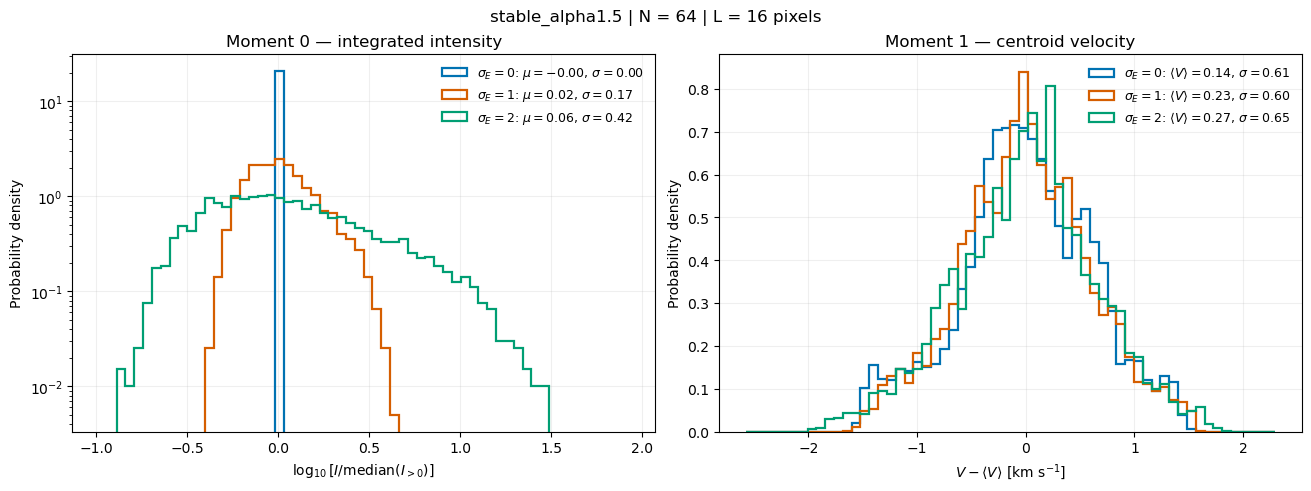

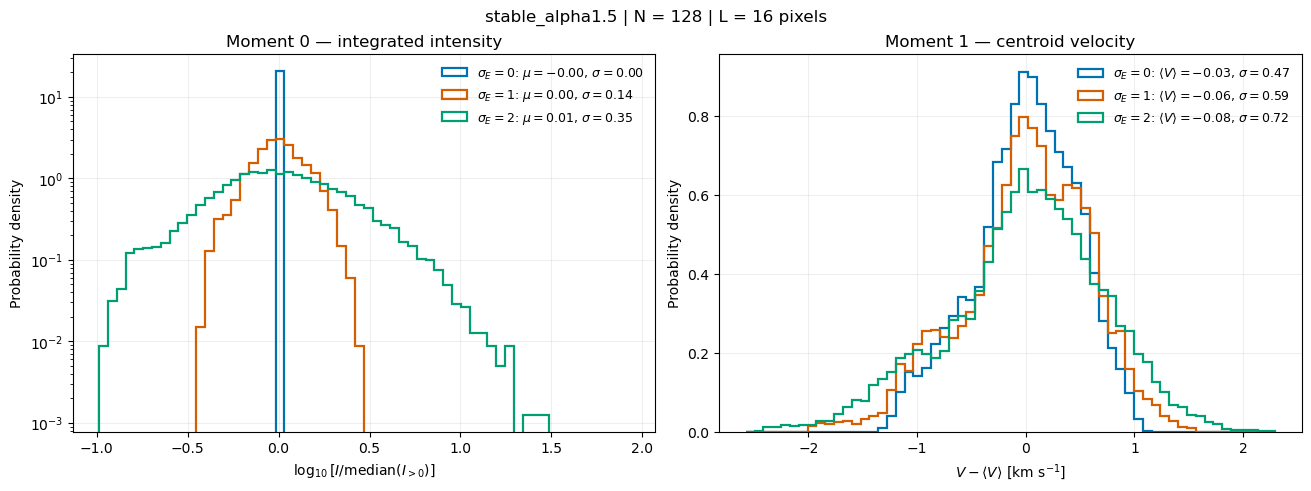

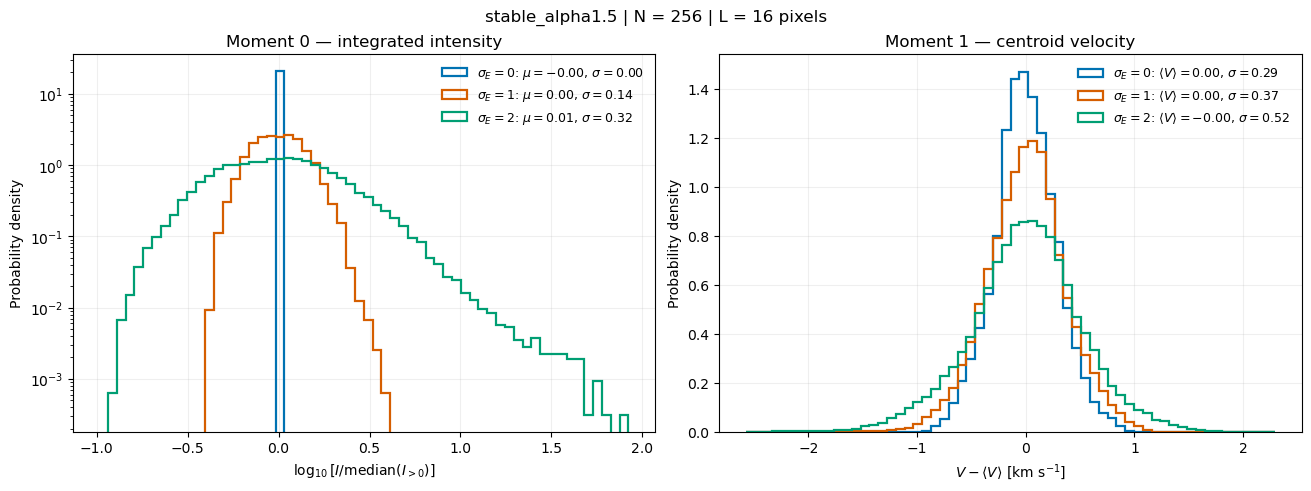

In [11]:
def common_edges(samples, quantity, bins):
    if not isinstance(bins, (int, np.integer)) or bins < 1:
        raise ValueError("Number of bins must be a positive integer")
    values = np.concatenate([d[quantity] for d in samples.values()])
    return np.histogram_bin_edges(values, bins=bins)

brightness_edges = common_edges(samples, "brightness", BRIGHTNESS_BINS)
velocity_edges = common_edges(samples, "velocity", VELOCITY_BINS)


def plot_moment_pdfs(samples, N, brightness_edges, velocity_edges):
    if STAT not in ("density", "count"):
        raise ValueError("STAT must be 'density' or 'count'")
    fig, (ax_i, ax_v) = plt.subplots(1, 2, figsize=(13, 4.8), constrained_layout=True)
    for e in SIGE_VALUES:
        d = samples[N, e]
        brightness, velocity = d["brightness"], d["velocity"]
        label_i = (rf"$\sigma_E={e}$: $\mu={brightness.mean():.2f}$, "
                   rf"$\sigma={brightness.std(ddof=0):.2f}$")
        label_v = (rf"$\sigma_E={e}$: $\langle V\rangle={d['mean_v']:.2f}$, "
                   rf"$\sigma={d['sigma_v']:.2f}$")
        for ax, values, edges, label in (
            (ax_i, brightness, brightness_edges, label_i),
            (ax_v, velocity, velocity_edges, label_v),
        ):
            ax.hist(values, bins=edges, density=(STAT == "density"),
                    histtype="step", color=COLORS[e], linewidth=1.6, label=label)
    xlabel_i = {
        "log_normalized": r"$\log_{10}[I/\mathrm{median}(I_{>0})]$",
        "normalized": r"$I/\mathrm{median}(I_{>0})$",
        "log": r"$\log_{10}(I)$ [I in native FITS units]",
        "raw": RAW_MOM0_LABEL,
    }[BRIGHTNESS_MODE]
    ax_i.set(title="Moment 0 — integrated intensity", xlabel=xlabel_i)
    xlabel_v = (r"$V-\langle V\rangle$" if CENTER_VELOCITY else r"$V$")
    ax_v.set(title="Moment 1 — centroid velocity",
             xlabel=xlabel_v + f" [{VELOCITY_UNIT_LABEL}]")
    for ax in (ax_i, ax_v):
        ax.set_ylabel("Probability density" if STAT == "density" else "Pixel count")
        if LOG_Y:
            ax.set_yscale("log")
        ax.legend(frameon=False, fontsize=9)
        ax.grid(alpha=0.2)
    if BRIGHTNESS_XLIM is not None:
        ax_i.set_xlim(*BRIGHTNESS_XLIM)
    if VELOCITY_XLIM is not None:
        ax_v.set_xlim(*VELOCITY_XLIM)
    ax_i.set_yscale("log")
    fig.suptitle(f"{MODEL} | N = {N} | L = {L} pixels")
    return fig, (ax_i, ax_v)

figures = {}
for N in N_VALUES:
    fig, axes = plot_moment_pdfs(samples, N, brightness_edges, velocity_edges)
    figures[N] = fig
    plt.show()


## Export or select one N
Set `N_VALUES = (128,)` in the configuration to load and plot only that batch. After changing transformations or bin settings, rerun from the loading cell. For ordinary histograms choose `BRIGHTNESS_MODE = "raw"`, `CENTER_VELOCITY = False`, and optionally `STAT = "count"`.

The following cell optionally exports each 1×2 figure as PNG and PDF. Actual moment FITS files are needed to produce your science plots; this notebook contains no example data or fabricated outputs.


In [12]:
if SAVE_FIGURES:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for N, fig in figures.items():
        stem = f"moment_PDFs_{MODEL}_N{N}_L{L}_{BRIGHTNESS_MODE}"
        for ext in ("png", "pdf"):
            output = OUTPUT_DIR / f"{stem}.{ext}"
            fig.savefig(output, dpi=300, bbox_inches="tight")
            print(output.resolve())


C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\moment_PDFs_stable_alpha1.5_N64_L16_log_normalized.png
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\moment_PDFs_stable_alpha1.5_N64_L16_log_normalized.pdf
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\moment_PDFs_stable_alpha1.5_N128_L16_log_normalized.png
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\moment_PDFs_stable_alpha1.5_N128_L16_log_normalized.pdf
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\moment_PDFs_stable_alpha1.5_N256_L16_log_normalized.png
C:\Users\javas\Dropbox\GitHub\VIENTO\fake_maps_gs\synthetic_experiments_V0.1\viento_pipeline\Imgs\moment_PDFs_stable_alpha1.5_N256_L16_log_normalized.pdf
